# Jupiter's light-deflection contribution to satellite occultation — Figure 3

Compute the correction amplitude $C_E$ for a stellar occultation by a satellite
on a circular orbit with Ganymede's adopted orbital radius. The curves show
the dependence on the observer–Jupiter–target (OMT) angle for two fixed
observer-to-Jupiter distances, 3.9 and 6.5 au.

This notebook accompanies the article; derivations are given there. The
geometry is idealized, with a star at infinity and Jupiter as the sole
deflector. It does not describe a particular epoch or an actual satellite
ephemeris. No solar contribution is included.

**Requirements:** NumPy, Astropy and Matplotlib, with the repository's
`light_deflection.py` in the same directory or on the Python path. No SPICE,
kernel file or ephemeris module is needed. Restart the Python kernel and run
the cells in order. The figure is saved as `OMT.pdf` in the working
directory, overwriting a file with that name if present.


In [1]:
import numpy as np
import astropy.units as u
import astropy.constants as const
from astropy.coordinates import CartesianRepresentation
import matplotlib.pyplot as plt

from light_deflection import delta_kpn, calc_alpha_star, calc_CE


## Fixed parameters

| Parameter | Value |
|---|---|
| Jupiter mass | $1.8986\times10^{27}$ kg |
| Observer-to-Jupiter distances $D_J$ | 4.2 and 6.2 au |
| Circular satellite-orbit radius $r$ | 1,070,400 km |
| Adopted Jupiter radius $R_J$ | 69,911 km |

The stellar deflection is evaluated analytically at infinity with
`calc_alpha_star`; there is no finite stellar-distance parameter. All
deflection functions use $\gamma=1$.


In [2]:
jupiter_GM = (const.G * (1.8986e27 * u.kg)).to(u.km**3 / u.s**2)
jupiter_distances = np.array([4.2, 6.2]) * u.au
orbit_radius = 1070400 * u.km
jupiter_radius = 69911 * u.km

# Independent samples of the original full-orbit sweep, without singular endpoints.
omt_angles = np.arange(1, 180) * u.deg


## Geometry and vectorized correction

Let O be the observer, M Jupiter and T the satellite. Put the observer at the
origin and Jupiter at $(D_J,0,0)$. For $\beta=\angle OMT$, place the target at
$$\boldsymbol x_T=(D_J-r\cos\beta,\ r\sin\beta,\ 0).$$
Thus $\beta=0$ is the near-side alignment and $\beta=180^\circ$ the far-side
alignment. The target distance is computed from this geometry,
$D_E=\|\boldsymbol x_T\|$; it is not set equal to $D_J$.

The star lies at infinity along the target's geometric sightline. Its angular
separation from Jupiter is the **observer-centered angle**
$\psi=\operatorname{atan2}(y_T,x_T)$, distinct from the OMT angle $\beta$.
For the helper's vector convention, the infinite-distance stellar deflection
is $\delta\hat{\boldsymbol k}_\star=
\alpha_\star(\sin\psi,-\cos\psi,0)$. Evaluate the finite-target deflection
with `delta_kpn` and compute
$$C_E=D_E\left\|\delta\hat{\boldsymbol k}_T-
\delta\hat{\boldsymbol k}_\star\right\|.$$

The calculation broadcasts over both Jupiter distances and all OMT angles.
Exact alignments are omitted
because the point-mass stellar-deflection expression is singular there.


In [3]:
def satellite_correction_grid(gm, planet_distances, orbit_radius, omt_angles):
    """Compute C_E for a circular satellite orbit and an aligned star at infinity.

    Parameters
    ----------
    gm : astropy.units.Quantity
        Planetary gravitational parameter, with length**3 / time**2 units.
    planet_distances : astropy.units.Quantity
        One-dimensional array of observer-to-planet distances, each greater
        than orbit_radius. The planet is placed on the positive x-axis.
    orbit_radius : astropy.units.Quantity
        Positive scalar satellite-orbit radius.
    omt_angles : astropy.units.Quantity
        One-dimensional array of angles at the planet, strictly between
        0 and 180 degrees. Zero denotes the near-side alignment.

    Returns
    -------
    astropy.units.Quantity
        Correction amplitudes in km, shape (n_planet_distances, n_angles).
        Row i corresponds to planet_distances[i]. No plotting is performed.

    Notes
    -----
    The stellar ray is aligned with the target's geometric observer-centered
    direction. The function evaluates the monopole model even for sightlines
    inside the projected planetary disk; such points are shaded in the plot.
    """
    distances = u.Quantity(planet_distances).to(u.km)
    radius = u.Quantity(orbit_radius).to(u.km)
    beta = u.Quantity(omt_angles).to(u.rad)
    if distances.ndim != 1 or beta.ndim != 1:
        raise ValueError('planet_distances and omt_angles must be one-dimensional.')
    if not radius.isscalar or radius <= 0*u.km:
        raise ValueError('orbit_radius must be a positive scalar length.')
    if np.any(distances <= radius):
        raise ValueError('The observer must lie outside the satellite orbit.')
    if np.any((beta <= 0*u.rad) | (beta >= np.pi*u.rad)):
        raise ValueError('OMT angles must lie strictly between 0 and 180 degrees.')

    planet = CartesianRepresentation(distances[:, None], 0*u.km, 0*u.km)
    orbital_offset = CartesianRepresentation(-radius*np.cos(beta), radius*np.sin(beta), 0*u.km)
    target = planet + orbital_offset
    target_distance = target.norm()
    psi = np.arctan2(target.y, target.x)

    # Use the known orbital offset directly as r_MT, avoiding subtraction of
    # two large observer-centered position vectors.
    delta_target = delta_kpn(gm, vec_rso=-target, vec_rao=-planet, vec_ras=orbital_offset)
    alpha_star_rad = calc_alpha_star(gm, distances[:, None], psi).to_value(
        u.rad, equivalencies=u.dimensionless_angles()
    )
    delta_star = CartesianRepresentation(
        np.sin(psi), -np.cos(psi), np.zeros(psi.shape)
    ) * alpha_star_rad
    return calc_CE(target_distance, delta_target, delta_star).to(u.km)


In [4]:
corrections = satellite_correction_grid(
    jupiter_GM, jupiter_distances, orbit_radius, omt_angles
)


## Planetary-limb markers

Retain the original distant-observer approximation for the two limb markers:
$$\beta_{\rm near}\simeq\arcsin(R_J/r),\qquad
\beta_{\rm far}\simeq180^\circ-\arcsin(R_J/r).$$
This gives approximately 3.74° and 176.26°, so a single pair of markers is
used for both curves. For a finite $D_J$, the exact crossings of the aligned
stellar sightline are shifted by $-\arcsin(R_J/D_J)$ from these approximate
values. That shift is below 0.007° for the adopted distances and is much
smaller than the 1° sampling. This approximation affects only the markers,
not the target geometry or the deflection calculation.

The gray bands indicate sightlines projected onto Jupiter's disk in this
approximation. Their plotted corrections are formal monopole values, not
observable stellar occultations by the satellite through Jupiter's opaque
disk. The adopted spherical radius is used only to draw these bands.


In [5]:
limb_angle = np.arcsin((jupiter_radius / orbit_radius).to_value(u.one)) * u.rad
near_limb = limb_angle.to_value(u.deg)
far_limb = 180 - near_limb
print(f'Approximate OMT limb crossings: {near_limb:.2f}° and {far_limb:.2f}°')


Approximate OMT limb crossings: 3.74° and 176.26°


## Figure 3

Plot the two rows of `corrections` against OMT angle.


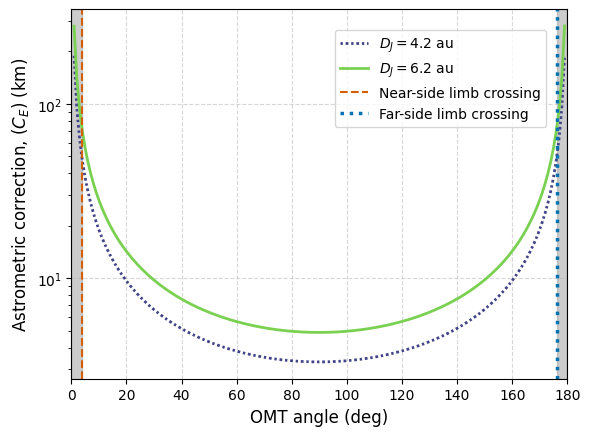

In [6]:
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(jupiter_distances)))
line_styles = [(0, (0.85, 1, 1, 1)), '-']

fig, ax = plt.subplots(figsize=(6.4, 4.8))
for i, (distance, curve, color) in enumerate(zip(jupiter_distances, corrections, colors)):
    ax.plot(omt_angles.to_value(u.deg), curve.to_value(u.km),
            color=color, linestyle=line_styles[i % len(line_styles)], linewidth=2,
            label=rf'$D_J={distance.to_value(u.au):g}$ au')

ax.axvspan(0, near_limb, color='grey', alpha=0.4, zorder=0)
ax.axvspan(far_limb, 180, color='grey', alpha=0.4, zorder=0)
ax.axvline(near_limb, color='#d55e00', linestyle='--', linewidth=1.5,
           label='Near-side limb crossing')
ax.axvline(far_limb, color='#0072b2', linestyle=':', linewidth=2.5,
           label='Far-side limb crossing')

ax.set(xlim=(0, 180), yscale='log')
ax.set_xlabel('OMT angle (deg)', fontsize=12)
ax.set_ylabel(r'Astrometric correction, $(C_E)$ (km)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', borderaxespad=1.5)
fig.savefig('OMT.pdf', bbox_inches='tight')
plt.show()
